> Notebook-friendly copy of `part-II/4.4-ocean-regimes-identification-exercises.ipynb`, generated by `tools/make_live.py`. Edit the book notebook, not this file.

In [7]:
# --- Préparation de l'environnement (générée automatiquement, hors exercice) ---
# Sur Colab/Kaggle, certains paquets ne sont pas installés par défaut.
# Si tout est déjà installé, cette cellule ne fait rien.
import importlib.util   # outils pour vérifier si un module Python est disponible
import subprocess       # permet de lancer une commande système (ici : pip)
import sys              # donne accès à l'interpréteur Python en cours (sys.executable)

# Pour chaque module requis (pooch et xarray) ...
for module, package in {"pooch": "pooch", "xarray": "xarray"}.items():
    # ... si le module est introuvable ...
    if importlib.util.find_spec(module) is None:
        # ... on l'installe silencieusement (-q) avec pip ; check=True lève une erreur si l'installation échoue
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", package], check=True)

# 4.4) (Exercise) Ocean Regimes Identification

<img src='https://github.com/gse-unil/2026_MLEES_book/blob/main/live/part-II/_static/seafoam.jpg?raw=1'>

<center>
Photo Credits: <a href="https://unsplash.com/photos/zCMWw56qseM">Sea Foam</a> by <a href="https://unsplash.com/@unstable_affliction">Ivan Bandura</a> licensed under the <a href='https://unsplash.com/license'>Unsplash License</a>
</center>


>*A frequently asked question related to this work is “Which mixing processes matter most for climate?” As with many alluringly comprehensive sounding questions, the answer is “it depends.”* <br>
> $\qquad$ MacKinnon, Jennifer A., et al. <br>$\qquad$"Climate process team on internal wave–driven ocean mixing." <br>$\qquad$ Bulletin of the American Meteorological Society 98.11 (2017): 2429-2454.

In week 4's final notebook, we will perform clustering to identify regimes in data taken from the realistic numerical ocean model [Estimating the Circulation and Climate of the Ocean](https://www.ecco-group.org/products-ECCO-V4r4.htm). Sonnewald et al. point out that finding robust regimes is intractable with a naïve approach, so we will be using reduced dimensionality data.

It is worth pointing out, however, that the reduction was done with an equation instead of one of the algorithms we discussed this week. If you're interested in the full details, you can check out [Sonnewald et al. (2019)](https://doi.org/10.1029/2018EA000519)

**🎯 Learning objectives**

- Cluster dimensionality-reduced data to identify ocean regimes in output from a numerical ocean model (Sonnewald et al.)
- Process the dataset with xarray, the standard tool for climate data
- Train a k-means model and evaluate how well it identifies the regimes

**Setup**

First, let's import a few common modules, ensure MatplotLib plots figures inline and prepare a function to save the figures. We also check that Python 3.5 or later is installed (although Python 2.x may work, it is deprecated so we strongly recommend you use Python 3 instead), as well as Scikit-Learn ≥0.20.

In [8]:
# Imports courants
import numpy as np     # calcul numérique (tableaux)
import os              # gestion des fichiers et dossiers
import xarray as xr    # tableaux multidimensionnels avec coordonnées nommées (lat, lon...) : l'outil standard pour les données climatiques
import pooch           # téléchargement de fichiers avec vérification d'intégrité

# Graine aléatoire fixe pour que les résultats soient identiques d'une exécution à l'autre
rnd_seed = 42
rnd_gen = np.random.default_rng(rnd_seed)   # générateur de nombres aléatoires initialisé avec la graine

# Pour de jolies figures
%matplotlib inline
import matplotlib as mpl            # réglages globaux de matplotlib
import matplotlib.pyplot as plt     # interface de tracé de graphiques
mpl.rc('axes', labelsize=14)        # taille de police des titres d'axes
mpl.rc('xtick', labelsize=12)       # taille de police des graduations en x
mpl.rc('ytick', labelsize=12)       # taille de police des graduations en y

# Dossier où sauvegarder les figures (dossier _files/ partagé pour cette partie)
IMAGES_PATH = "_files"
os.makedirs(IMAGES_PATH, exist_ok=True)   # crée le dossier s'il n'existe pas

# Fonction utilitaire pour enregistrer la figure courante sur le disque
def save_fig(fig_id, tight_layout=True, fig_extension="png", resolution=300):
    path = os.path.join(IMAGES_PATH, fig_id + "." + fig_extension)   # chemin complet, ex. _files/ma_figure.png
    print("Saving figure", fig_id)                                    # message de confirmation
    if tight_layout:
        plt.tight_layout()                                            # ajuste les marges pour éviter les chevauchements
    plt.savefig(path, format=fig_extension, dpi=resolution)           # enregistre l'image (300 dpi par défaut)

Here we're going to import the [StandardScaler](https://duckduckgo.com/sklearn.preprocessing.standardscaler) function from scikit's preprocessing tools, import the [scikit clustering library](https://duckduckgo.com/sklearn.clustering), and set up the colormap that we will use when plotting.

In [9]:
from sklearn.preprocessing import StandardScaler  # pour standardiser les données (moyenne 0, écart-type 1)
import sklearn.cluster as cluster                  # module de clustering, raccourci 'cluster' (-> cluster.KMeans)

from matplotlib.colors import LinearSegmentedColormap, ListedColormap   # outils pour créer des palettes de couleurs
colors = ['royalblue', 'cyan','yellow', 'orange', 'magenta', 'red']    # une couleur par régime final (6 au total)
mycmap = ListedColormap(colors)                    # palette de 6 couleurs utilisée pour la carte finale

**Data Preprocessing**

The first thing we need to do is retrieve the list of files we'll be working on. We'll rely on pooch to access the files hosted on the cloud.

In [10]:
# Télécharge et met en cache une copie vérifiée du jeu de données THOR (régimes océaniques)
data_url = "https://raw.githubusercontent.com/gse-unil/2026_MLEES_book/main/data/part-II/S4_3_THOR_data.zip"   # adresse du fichier zip
hash = "3f41661c7a087fa7d7af1d2a8baf95c065468f8a415b8514baedda2f5bc18bb5"                                       # empreinte SHA-256 attendue

files = pooch.retrieve(data_url, known_hash=hash, processor=pooch.Unzip())  # télécharge le zip, vérifie le hash, décompresse -> liste des chemins de fichiers
[print(filename) for filename in files];   # affiche chaque chemin ; le « ; » final évite d'afficher la liste renvoyée

/root/.cache/pooch/d70ddd3cea8fe695fa7b99473a0ec8b8-S4_3_THOR_data.zip.unzip/BPT.npy
/root/.cache/pooch/d70ddd3cea8fe695fa7b99473a0ec8b8-S4_3_THOR_data.zip.unzip/curlA.npy
/root/.cache/pooch/d70ddd3cea8fe695fa7b99473a0ec8b8-S4_3_THOR_data.zip.unzip/curlB.npy
/root/.cache/pooch/d70ddd3cea8fe695fa7b99473a0ec8b8-S4_3_THOR_data.zip.unzip/curlTau.npy
/root/.cache/pooch/d70ddd3cea8fe695fa7b99473a0ec8b8-S4_3_THOR_data.zip.unzip/noiseMask.npy
/root/.cache/pooch/d70ddd3cea8fe695fa7b99473a0ec8b8-S4_3_THOR_data.zip.unzip/curlCori.npy


And now that we have a set of files to load, let's set up a dictionary with the variable names as keys and the data in numpy array format as the values.

In [11]:
# Récupère le nom de chaque variable à partir du chemin de son fichier
var_names = []
[var_names.append(path.split('/')[-1][:-4]) for path in files]  # split('/')[-1] = nom du fichier ; [:-4] enlève '.npy' (ex. 'BPT')

# Construit un dictionnaire : nom de variable -> tableau de données
data_dict = {}
for idx, val in enumerate(var_names):   # idx = position, val = nom de la variable
    data_dict[val] = np.load(files[idx]).T  # charge le .npy ; .T = transposée -> forme (lat=360, lon=720)

# Affiche le nom de chaque variable chargée et la forme de son tableau
# {item[0]:<15} = nom aligné à gauche sur 15 caractères
[print(f'Varname: {item[0]:<15} Shape: {item[1].shape}') for item in data_dict.items()];

Varname: BPT             Shape: (360, 720)
Varname: curlA           Shape: (360, 720)
Varname: curlB           Shape: (360, 720)
Varname: curlTau         Shape: (360, 720)
Varname: noiseMask       Shape: (360, 720)
Varname: curlCori        Shape: (360, 720)


We now have a dictionary that uses the filename as the key! Feel free to explore the data (e.g., loading the keys, checking the shape of the arrays, plotting)

In [12]:
# Espace libre pour explorer le dictionnaire de données (ex. data_dict.keys(), data_dict['BPT'].shape...)

We're eventually going to have an array of cluster classes that we're going to use to label dynamic regimes in the ocean. Let's make an array full of NaN (not-a-number) values that has the same shape as our other variables and store it in the data dictionary.

In [13]:
# Crée une carte vide (remplie de NaN) de même forme que les autres variables ; elle recevra plus tard le n° de cluster de chaque point
data_dict['clusters'] = np.full_like(data_dict['BPT'],np.nan)

## Reformatting as Xarray

In the original paper, this data was loaded as numpy arrays. However, we'll take this opportunity to demonstrate the same procedure while relying on xarray. First, let's instantiate a blank dataset.<br><br>

### Q1) Make a blank xarray dataset.<br>
*Hint: Look at the xarray [documentation](https://duckduckgo.com/?q=xarray+dataset)*

In [14]:
# Crée un Dataset xarray vide (sans paramètre)
# Dataset = « boîte » qui contiendra plusieurs DataArrays partageant les mêmes coordonnées (lat, lon)
ds = xr.Dataset()

<img src='https://github.com/gse-unil/2026_MLEES_book/blob/main/live/part-II/_static/xarray_dataset_diagram.png?raw=1'>
<center> Image taken from the xarray <a href='https://xarray.pydata.org/en/stable/user-guide/data-structures.html#:~:text=Dataset-,xarray.,from%20the%20netCDF%20file%20format.'> <i>Data Structure documentation</i> </a> </center>

In order to build the dataset, we're going to need a set of coordinate vectors that help us map out our data! For our data, we have two axes corresponding to longitude ($\lambda$) and latitude ($\phi$).

We don't know much about how many lat/lon points we have, so let's explore one of the variables to make sense of the data the shape of one of the numpy arrays.

### Q2) Visualize the data using a plot and printing the shape of the data to the console output.

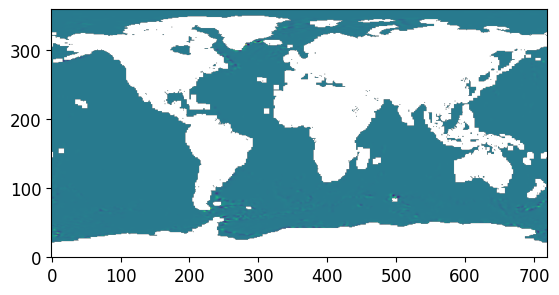

In [15]:
# Affiche une image des couples de pression au fond (Bottom Pressure Torques, BPT)
plt.imshow( data_dict['BPT'] , origin='lower')  # affiche le tableau 2D comme une image ; origin='lower' -> ligne 0 en bas (sud en bas)

In [16]:
# Garde en mémoire la forme des données et l'affiche
data_shape = data_dict['BPT'].shape  # (nb de latitudes, nb de longitudes)
print(data_shape)

(360, 720)


Now that we know how the resolution of our data, we can prepare a set of axis arrays. We will use these to organize the data we will feed into the dataset.

### Q3) Prepare the latitude and longitude arrays to be used as axes for our dataset

*Hint 1: You can build ordered numpy arrays using, e.g., [numpy.linspace](https://numpy.org/doc/stable/reference/generated/numpy.linspace.html) and [numpy.arange](https://numpy.org/doc/stable/reference/generated/numpy.arange.html)*

*Hint 2: You can rely on the data_shape variable we loaded previously to know how many points you need along each axis*

In [17]:
# Prépare les axes de latitude et de longitude
# Grille de 0.5° : 360 latitudes et 720 longitudes, valeurs au CENTRE de chaque case
lat = np.linspace(-89.75, 89.75, data_shape[0])    # de -89.75 à 89.75, data_shape[0] = 360 valeurs régulièrement espacées
lon = np.linspace(-179.75, 179.75, data_shape[1])  # de -179.75 à 179.75, data_shape[1] = 720 valeurs

Now that we have the axes we need, we can build xarray [*data arrays*](https://xarray.pydata.org/en/stable/generated/xarray.DataArray.html) for each data variable. Since we'll be doing it several times, let's go ahead and defined a function that does this for us!

### Q4) Define a function that takes in: 1) an array name, 2) a numpy array, 3) a lat vector, and 4) a lon vector. The function should return a dataArray with lat-lon as the coordinate dimensions

In [18]:
# Fonction qui transforme un tableau numpy 2D en DataArray xarray
# DataArray = tableau numpy + noms de dimensions + coordonnées + nom
def np_to_xr(array_name, array, lat, lon):
    # Construction du DataArray
    da = xr.DataArray(data = array,   # données à stocker

                  # Noms des dimensions : axe 0 = lat (lignes), axe 1 = lon (colonnes)
                  dims = ['lat', 'lon'],

                  # Dictionnaire qui associe à chaque dimension ses valeurs de coordonnées
                  coords = {'lat':lat,    # valeurs de latitude pour l'axe 'lat'
                            'lon':lon},   # valeurs de longitude pour l'axe 'lon'

                  name=array_name)  # nom de la variable (ex. 'BPT')
    return da  # renvoie le DataArray construit

We're now ready to build our data array! Let's iterate through the items and merge our blank dataset with the data arrays we create.

### Q5) Build the dataset from the data dictionary

*Hint: We'll be using the xarray merge command to put everything together.*

In [19]:
# Le reste du notebook suppose que le dataset s'appelle ds

# Pour chaque variable du dictionnaire (key = nom, item = tableau numpy)...
for key, item in data_dict.items():
    # ... on la convertit en DataArray avec notre fonction np_to_xr
    da = np_to_xr(key, item, lat, lon)

    # ... puis on la fusionne avec le dataset -> ds grossit d'une variable à chaque tour de boucle
    ds = xr.merge( [ds , da ] )

Congratulations! You should now have a nicely set up xarray dataset. This let's you access a ton of nice features, e.g.:
> Data plotting by calling, e.g., `ds.BPT.plot.imshow(cmap='ocean')`
>
> Find statistical measures of all variables at once! (e.g.: `ds.std()`, `ds.mean()`)

In [20]:
# Espace libre pour explorer le dataset (ex. ds.BPT.plot.imshow(cmap='ocean'), ds.mean()...)

Now we want to find clusters of data considering each grid point as a datapoint with 5 dimensional data. However, we went through a lot of work to get the data nicely associated with a lat and lon - do we really want to undo that?

Luckily, xarray developers foresaw the need to group dimensions together. Let's create a 'flat' version of our dataset using the [`stack`](https://xarray.pydata.org/en/stable/generated/xarray.DataArray.stack.html) method. Let's make a flattened version of our dataset.

### Q6) Store a flattened version of our dataset

*Hint 1: You'll need to pass a dictionary with the 'new' stacked dimension name as the key and the 'flattened' dimensions as the values.*

*Hint 2: xarrays have a ['.values' attribute](https://xarray.pydata.org/en/stable/generated/xarray.DataArray.values.html) that return their data as a numpy array.*

In [21]:
# « Aplatit » la grille 2D (lat, lon) en une seule dimension 'points' (360*720 = 259200 points)
# Chaque point de grille devient un échantillon ; lat et lon restent mémorisées pour pouvoir reconstruire la carte
stacked = ds.stack( { 'points' :[ 'lat' , 'lon' ] } )

In [22]:
# Vérifie la forme des données
print(stacked.to_array().values.shape)  # to_array = empile les variables ; .values = numpy ; forme (nb variables, nb points)

(7, 259200)


So far we've ignored an important point - we're supposed to have 5 variables, not 6! As you may have guessed, `noiseMask` helps us throw away data we dont want (e.g., from land mass or bad pixels).

We're now going to clean up the stacked dataset using the noise mask. Relax and read through the code, since there won't be a question in this part :)

In [23]:
# On ne garde que les points où noiseMask = 1 (noiseMask est binaire : 1 = océan valide, 0 = terre ou pixel douteux)

print(f'Dataset shape before processing: {stacked.to_array().values.shape}')

print("Let's do some data cleaning!")
print(f'Points before cleaning: {len(stacked.BPT)}')                 # nombre de points avant nettoyage
stacked = stacked.where(stacked.noiseMask==1, drop=True)            # garde seulement les points valides ; drop=True supprime les autres
print(f'Points after cleaning: {len(stacked.BPT)}')                  # nombre de points après nettoyage

Dataset shape before processing: (7, 259200)
Let's do some data cleaning!
Points before cleaning: 259200
Points after cleaning: 149714


In [24]:
# La variable noiseMask ne sert plus : on la supprime

print('And drop the noisemask variable...')
print(f'Before dropping: {stacked.to_array().values.shape}')
stacked = stacked.drop_vars('noiseMask')  # il reste 5 variables physiques + clusters
print(f'Dataset shape after processing: {stacked.to_array().values.shape}')

And drop the noisemask variable...
Before dropping: (7, 149714)
Dataset shape after processing: (6, 149714)


We now have several thousand points which we want to divide into clusters using the kmeans clustering algorithm (you can check out the documentation for scikit's implementation of kmeans [here](https://scikit-learn.org/stable/modules/generated/sklearn.cluster.KMeans.html)).

You'll note that the algorithm expects the input data `X` to be fed as `(n_samples, n_features)`. This is the opposite of what we have! Let's go ahead and make a copy to a numpy array has the axes in the right order.

You'll need xarray's [`.to_array()`](https://xarray.pydata.org/en/stable/generated/xarray.Dataset.to_array.html) method and [`.values`](https://xarray.pydata.org/en/stable/generated/xarray.DataArray.values.html) parameter, as well as numpy's [`.moveaxis`](https://numpy.org/doc/stable/reference/generated/numpy.moveaxis.html) method.

### Q7) Load the datapoints into a numpy array following the convention where the 0th axis corresponds to the samples and the 1st axis corresponds to the features.

In [25]:
# scikit-learn veut un tableau (n_samples, n_features) = (points, variables) ; on a (variables, points) -> on échange les axes
input_data = np.moveaxis(stacked.drop_vars('clusters').to_array().values,  # retire 'clusters' (pas une entrée), empile les 5 variables -> numpy
                         0,          # axe source : l'axe 0 (les variables)...
                         1)          # ...déplacé en position 1 -> forme (points, 5 variables)

In [26]:
# Les données d'entrée ont-elles la bonne forme ?
print(input_data.shape)  # (nb de points océan, 5 variables)

(149714, 5)


## Kmeans clustering

In previous classes we discussed the importance of the scaling the data before implementing our algorithms. Now that our data is all but ready to be fed into an algorithm, let's make sure that it's been scaled.

### Q8) Scale the input data

*Hint 1: Import the [`StandardScaler`](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.StandardScaler.html) class from scikit and instantiate it*

*Hint 2: Update the input array to the one returned by the [`.fit_transform(X)`](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.StandardScaler.html#sklearn.preprocessing.StandardScaler.fit_transform) method*

In [27]:
# Les 5 variables ont des unités/ordres de grandeur différents ; KMeans utilise des DISTANCES,
# donc sans mise à l'échelle la variable la plus grande dominerait tout.
scaler = StandardScaler()                       # crée l'outil de standardisation
input_data = scaler.fit_transform(input_data)   # fit = calcule moyenne et écart-type de chaque colonne ; transform = (x - moyenne) / écart-type

Now we're finally ready to train our algorithm! Let's load up the kmeans model and find clusters in our data.

### Q9) Instantiate the kmeans clustering algorithm, and then fit it using 50 clusters, trying out 10 different initial centroids.

*Hint 1: `sklearn.cluster` was imported as `cluser` during the notebook setup! [Here is the scikit `KMeans` documentation](https://scikit-learn.org/stable/modules/generated/sklearn.cluster.KMeans.html).*

*Hint 2: Use the `fit_predict` method to organize the data into clusters*

*Warning! : Fitting the data may take some time (under a minute during the testing of the notebook)

In [28]:
# Crée le modèle K-means
kmeans = cluster.KMeans(n_clusters =50,     # 50 groupes (volontairement beaucoup, on les regroupera ensuite)
                        random_state =42,   # graine -> résultat reproductible
                        n_init =10,         # 10 initialisations différentes des centres ; garde la meilleure (inertie la plus faible)
                       verbose = 1)         # affiche la progression pour vérifier que tout tourne

In [29]:
# fit + predict en une fois : entraîne K-means sur les données standardisées et renvoie le n° de cluster (0-49) de chaque point
cluster_labels = kmeans.fit_predict(input_data)

Initialization complete
Iteration 0, inertia 178539.00982924117.
Iteration 1, inertia 162261.46194163503.
Iteration 2, inertia 158116.0026155056.
Iteration 3, inertia 156154.94948264517.
Iteration 4, inertia 154655.68230869833.
Iteration 5, inertia 153702.1358092489.
Iteration 6, inertia 152994.4960641377.
Iteration 7, inertia 152528.2811049643.
Iteration 8, inertia 152108.36268125765.
Iteration 9, inertia 151717.8292321467.
Iteration 10, inertia 151335.17681823997.
Iteration 11, inertia 150967.80178906437.
Iteration 12, inertia 150535.0968668106.
Iteration 13, inertia 150130.06375057463.
Iteration 14, inertia 149635.23733039762.
Iteration 15, inertia 149153.5443829257.
Iteration 16, inertia 148761.87688258116.
Iteration 17, inertia 148454.96770510706.
Iteration 18, inertia 148201.86773876465.
Iteration 19, inertia 147982.7837860522.
Iteration 20, inertia 147743.02515719907.
Iteration 21, inertia 147451.36197518025.
Iteration 22, inertia 147153.6496246658.
Iteration 23, inertia 146876.

We now have a set of cluster labels that group the data into 50 similar groups. Let's store it in our stacked dataset!

In [30]:
# Range le n° de cluster de chaque point dans la variable 'clusters' du dataset
stacked['clusters'].values = cluster_labels

## Visualization

We now have a set of labels, but they're stored in a flattened array. Since we'd like to see the data as a map, we still have some work to do. Let's go back to a 2D representation of our values.

### Q10) Turn the flattened xarray back into a set of 2D fields
*Hint*: xarrays have an [`.unstack` method](https://xarray.pydata.org/en/stable/generated/xarray.DataArray.unstack.html) that you will find to be very useful for this.

In [31]:
# Inverse de stack : la dimension 'points' redevient la grille (lat, lon) pour pouvoir faire une carte
# (les points supprimés au nettoyage, comme les terres, réapparaissent en NaN)
processed_ds = stacked.unstack()

Now we have an unstacked dataset, and can now easily plot out the clusters we found!

### Q11) Plot the 'cluster' variable using the built-in xarray function
*Hint: `.plot()` [link text](https://xarray.pydata.org/en/stable/generated/xarray.DataArray.plot.html) let's you access the xarray implementations of [`pcolormesh`](https://matplotlib.org/3.1.1/api/_as_gen/matplotlib.pyplot.pcolormesh.html) and [`imshow`](https://matplotlib.org/3.1.1/api/_as_gen/matplotlib.pyplot.imshow.html).*

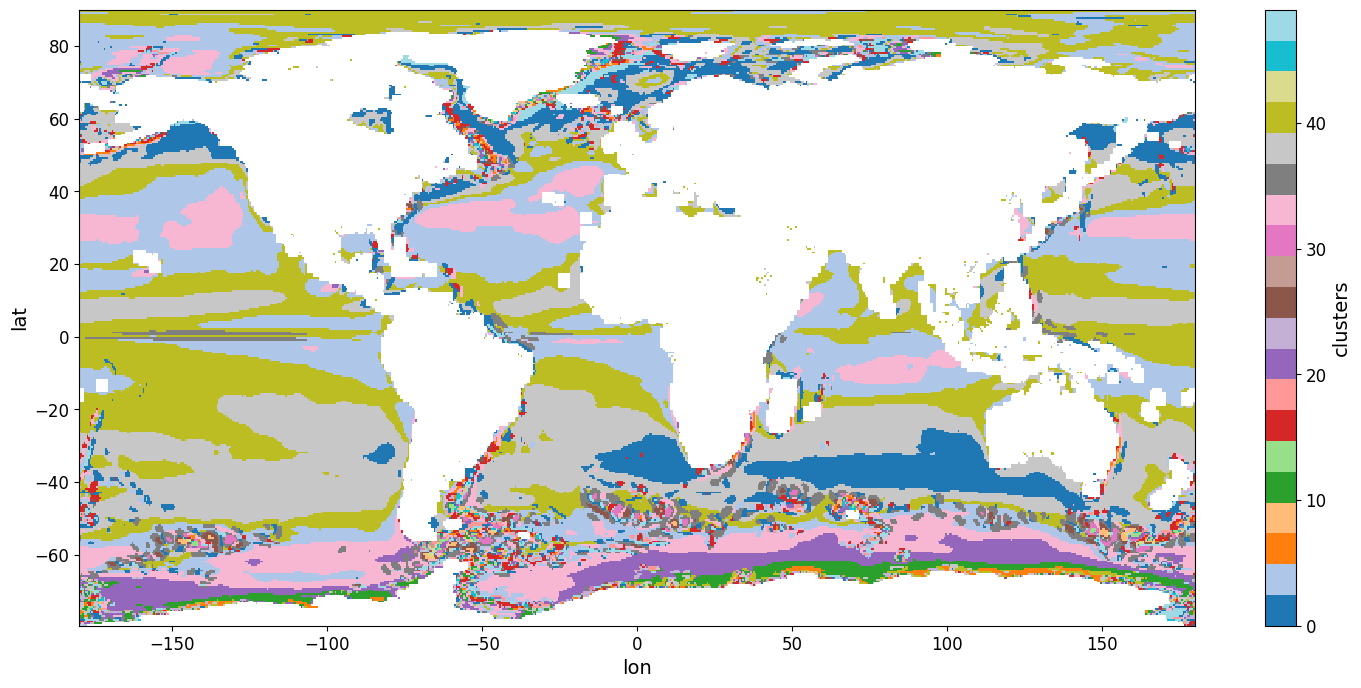

In [32]:
# Carte des 50 clusters ; xarray met automatiquement lat/lon sur les axes ; 'tab20' = palette de couleurs bien distinctes
processed_ds.clusters.plot.imshow(figsize=(18,8), cmap='tab20')

Compare your results to those from the paper:
<img src='https://github.com/gse-unil/2026_MLEES_book/blob/main/live/part-II/_static/THOR_50.png?raw=1'>

We now want to find the 5 most common regimes, and group the rest. This isn't straightforward, so we've gone ahead and prepared the code for you. Run through it and try to understand what the code is doing!

/usr/local/lib/python3.13/dist-packages/xarray/structure/concat.py:673: UserWarning: No index created for dimension clusters because variable clusters is not a coordinate. To create an index for clusters, please first call `.set_coords('clusters')` on this object.
  ds.expand_dims(dim_name, create_index_for_new_dim=create_index_for_new_dim)


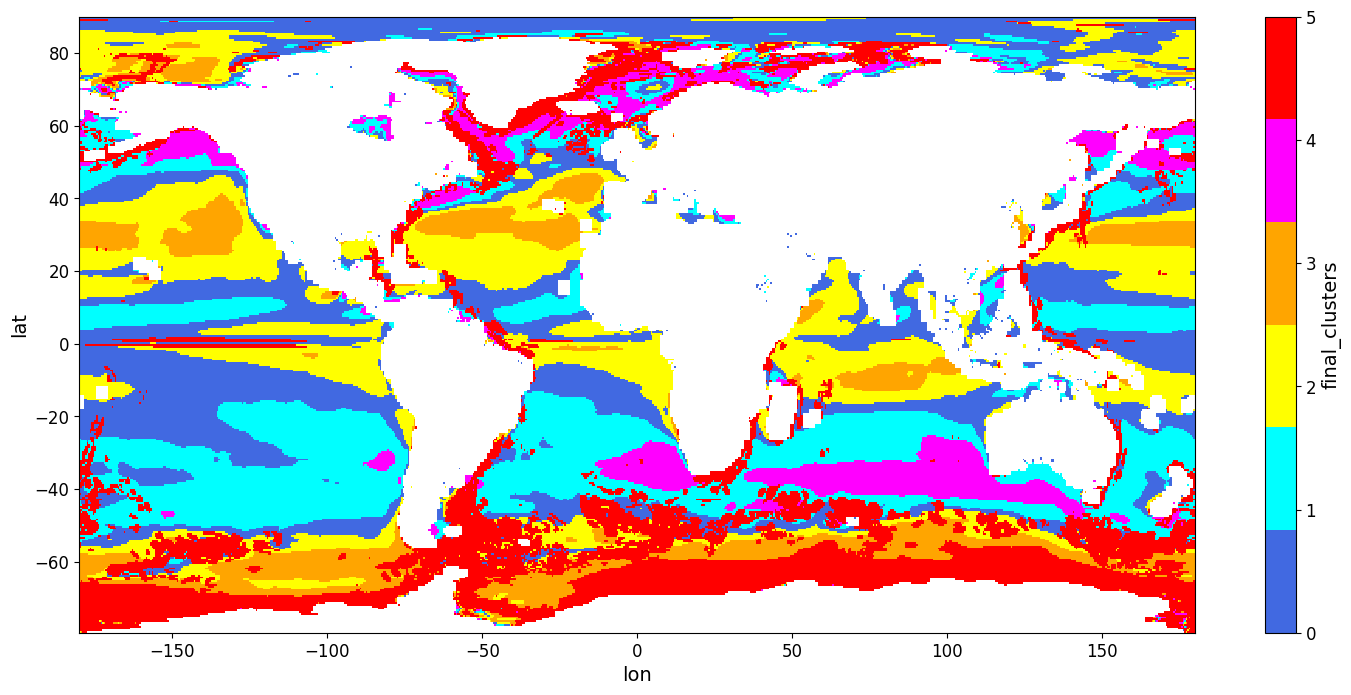

In [33]:
# Crée une variable remplie de -1 pour repérer facilement les points pas encore traités.
# Multiplier clusters par 0 garde les NaN des terres : le masque est donc appliqué automatiquement.
processed_ds['final_clusters'] = (processed_ds.clusters * 0) - 1

# Trouve les 5 clusters les plus fréquents :
# groupby + count = nombre de points par cluster ; sortby = tri croissant ; tail(5) = les 5 derniers (donc les plus grands)
top_clusters = processed_ds.groupby('clusters').count().sortby('BPT').tail(5).clusters.values

# Renumérote ces 5 clusters de 0 à 4
for idx, label in enumerate(top_clusters):
    # Masque True/False des points qui appartiennent à ce cluster
    indices = (processed_ds.clusters == label)

    processed_ds['final_clusters'].values[indices] = 4-idx  # le plus fréquent reçoit 0, le 5e reçoit 4

# Tous les points restants (encore à -1) forment le régime 5 « non-linéaire »
processed_ds['final_clusters'].values[processed_ds.final_clusters==-1] = 5

# Trace la carte des 6 régimes avec la palette de 6 couleurs définie au début
processed_ds.final_clusters.plot.imshow(cmap=mycmap, figsize=(18,8));

In [34]:
# Feel free to use this space

Compare it to the regimes found in the paper:
<img src='https://github.com/gse-unil/2026_MLEES_book/blob/main/live/part-II/_static/THOR_5.png?raw=1'>

The authors then went on to train neural networks ***to infer in-depth dynamics from data that is largely readily available from for example CMIP6 models, using NN methods to infer the source of predictive skill*** and ***to apply the trained Ensemble MLP to a climate model in order to assess circulation changes under global heating***.

For our purposes, however, we will say goodbye to *THOR* at this point 😃